In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
import numpy as np
!pip install pandas
import pandas as pd
!pip install seaborn
import seaborn as sns
plt.rcParams['figure.figsize'] = [8,5]
plt.rcParams['font.size'] =14

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [11]:
path = 'archive/Kaggle Dataset/'
df = pd.read_csv(path + 'song_data.csv', encoding='latin-1')
print('\nNumber of rows and columns in the data set: ', df.shape)
print('')
df.head()


Number of rows and columns in the data set:  (565, 44)



,year,semi_final,semi_draw_position,final_draw_position,country,artist_name,song_name,language,style,direct_qualifier_10,...,final_jury_votes,final_place,final_total_points,semi_place,semi_televote_points,semi_jury_points,semi_total_points,favourite_10,race,host_10
0,2023,1,1,20,Norway,Alessandra,Queen of Kings,English,Pop,0,...,11.0,5.0,268.0,6.0,102.0,NaN,102.0,0,unknown,0
1,2023,1,2,NaN,Malta,The Busker,Dance (Our Own Party),English,Pop,-,...,NaN,NaN,NaN,15.0,3.0,NaN,3.0,0,unknown,0
2,2023,1,3,5,Serbia,Luke Black,Samo mi se spava,"Serbian, English",Pop,0,...,6.0,24.0,30.0,10.0,37.0,NaN,37.0,0,unknown,0
3,2023,1,4,NaN,Latvia,Sudden Lights,Aija,English,Rock,-,...,NaN,NaN,NaN,11.0,34.0,NaN,34.0,0,unknown,0
4,2023,1,5,2,Portugal,Mimicat,Ai coração,Portuguese,Pop,0,...,9.0,23.0,59.0,9.0,74.0,NaN,74.0,0,unknown,0


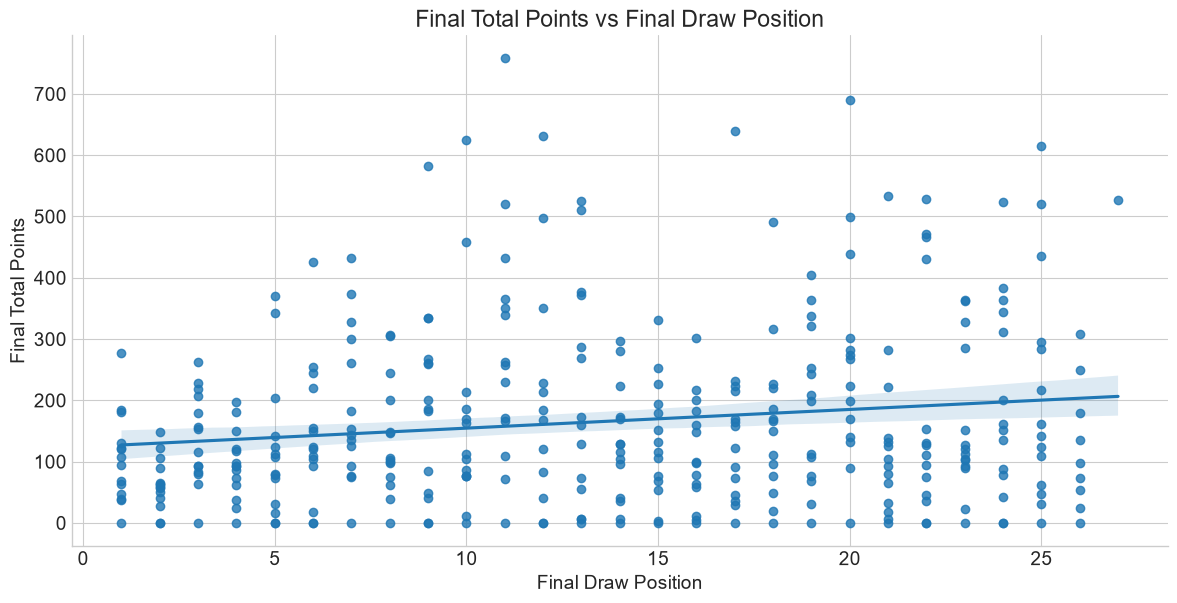

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df['final_draw_position'] = pd.to_numeric(df['final_draw_position'], errors='coerce')
df['final_total_points'] = pd.to_numeric(df['final_total_points'], errors='coerce')

df_clean = df.dropna(subset=['final_draw_position', 'final_total_points'])

sns.lmplot(x='final_draw_position', y='final_total_points',
           data=df_clean, aspect=2, height=6)

plt.xlabel('Final Draw Position')
plt.ylabel('Final Total Points')
plt.title('Final Total Points vs Final Draw Position')
plt.show()

In [13]:
from sklearn.linear_model import LinearRegression

X = df_clean[['final_draw_position']] 
y = df_clean['final_total_points']

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

print(f"Model slope:     {model.coef_[0]:.4f}")
print(f"Model intercept: {model.intercept_:.4f}")

Model slope:     3.0485
Model intercept: 124.0862


In [14]:
rng = np.random.RandomState(1)
X = 10 * rng.rand(100, 3)
y = 0.5 + np.dot(X, [1.5, -2., 1.])

model.fit(X, y)
print(model.intercept_)
print(model.coef_)

0.5000000000000033
[ 1.5 -2.   1. ]


In [15]:
from sklearn.preprocessing import PolynomialFeatures
x = np.array([2, 3, 4])
poly = PolynomialFeatures(3, include_bias=False)
poly.fit_transform(x[:, None])

array([[ 2.,  4.,  8.],
       [ 3.,  9., 27.],
       [ 4., 16., 64.]])

In [16]:
from sklearn.pipeline import make_pipeline
poly_model = make_pipeline(PolynomialFeatures(7),
                           LinearRegression())

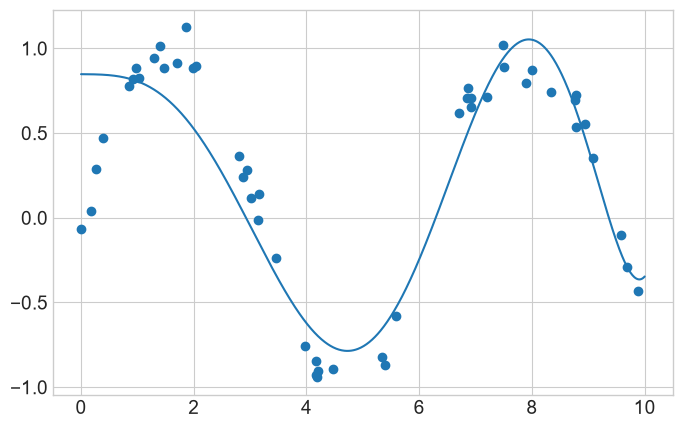

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

rng = np.random.RandomState(1)
x = 10 * rng.rand(50)
y = np.sin(x) + 0.1 * rng.randn(50)

xfit = np.linspace(0, 10, 1000)

poly_model = make_pipeline(PolynomialFeatures(7), LinearRegression())

poly_model.fit(x[:, np.newaxis], y)

yfit = poly_model.predict(xfit[:, np.newaxis])

plt.scatter(x, y)
plt.plot(xfit, yfit)
plt.show()

In [9]:
df.describe()

,year,final_draw_position,main_singers,backing_dancers,backing_singers,backing_instruments,instrument_10,final_televote_points,final_jury_points,final_televote_votes,final_jury_votes,final_place,final_total_points,semi_place,semi_televote_points,semi_jury_points,semi_total_points,favourite_10,host_10
count,565.000000,358.000000,565.000000,565.000000,565.000000,565.000000,565.000000,328.000000,328.000000,233.000000,233.000000,358.000000,358.000000,483.000000,243.000000,212.000000,483.000000,565.000000,565.000000
mean,2015.653097,13.371508,1.297345,0.884956,1.088496,0.837168,0.118584,90.539634,90.655488,15.184549,15.107296,13.391061,164.849162,9.192547,68.263374,67.575472,97.788820,0.024779,0.024779
std,4.312691,7.459619,0.854739,1.460789,1.624052,1.460484,0.323585,86.852074,74.096517,12.828622,9.868602,7.430208,143.603444,5.069863,50.617148,47.545328,73.844662,0.155588,0.155588
min,2009.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2012.000000,7.000000,1.000000,0.000000,0.000000,0.000000,0.000000,25.750000,36.000000,4.000000,7.000000,7.000000,68.250000,5.000000,24.500000,26.750000,43.000000,0.000000,0.000000
50%,2016.000000,13.000000,1.000000,0.000000,0.000000,0.000000,0.000000,59.000000,71.000000,11.000000,13.000000,13.000000,124.500000,9.000000,54.000000,58.000000,77.000000,0.000000,0.000000
75%,2019.000000,20.000000,1.000000,2.000000,2.000000,1.000000,0.000000,127.500000,126.000000,26.000000,22.000000,20.000000,225.250000,13.500000,104.500000,98.250000,134.000000,0.000000,0.000000
max,2023.000000,27.000000,6.000000,5.000000,5.000000,5.000000,1.000000,439.000000,382.000000,42.000000,39.000000,27.000000,758.000000,19.000000,204.000000,222.000000,403.000000,1.000000,1.000000
